<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/Jobsheet%20Dataset%20PBL/JS06_Regresi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JOBSHEET 06: REGRESI (SIMPLE, MULTIPLE, & SVR)
### Pemodelan Prediksi Harga Properti Multi-Kota Indonesia Menggunakan OLS Statsmodels, Regresi Linier Berganda, Regularisasi Ridge, dan Support Vector Regression (SVR RBF) Berbasis Dataset PBL RumahPoint
**Mata Kuliah:** Pembelajaran Mesin — Semester 5 (Tahun Akademik 2025/2026)  
**Mahasiswa:** Wahyudi Satriawan Hamid  
**NIM / Kelas:** 244107020137 / TI-3H  
**Program Studi:** D-IV Teknik Informatika — Jurusan Teknologi Informasi — Politeknik Negeri Malang  

---

---
## Bagian 1 — Pemuatan Data, Splitting Anti-Leakage, & EDA Korelasi Target

Pada bagian ini, dataset bersih `properti_multi_kota_clean.csv` dimuat menggunakan *Dual-Mode Loader*, fitur indikator domain deterministik `is_komersil` dibentuk, pembagian data latih-uji (*train-test split*) dilakukan di awal untuk mencegah kebocoran informasi (*data leakage*), daftar Top-15 `lokasi_bersih` dipelajari eksklusif dari data latih, dan korelasi fitur numerik dianalisis untuk menentukan prediktor terkuat.

In [23]:
# ==============================================================================
# BAGIAN 1.1: LINGKUNGAN KOMPUTASI, IMPORT LIBRARY, & LOADER DATA DUAL-MODE
# ==============================================================================
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Konfigurasi gaya visualisasi standar
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 100

print("=" * 80)
print("SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)")
print("=" * 80)
print(f"Versi Python        : {sys.version.split()[0]}")
print(f"Versi NumPy         : {np.__version__}")
print(f"Versi Pandas        : {pd.__version__}")
import sklearn
print(f"Versi Scikit-Learn  : {sklearn.__version__}")
import statsmodels
print(f"Versi Statsmodels   : {statsmodels.__version__}")

# Pemuatan data cerdas dual-mode
DATASET_FILENAME = "properti_multi_kota_clean.csv"
LOCAL_PATH = os.path.join("..", "Dataset", DATASET_FILENAME)
GITHUB_RAW_URL = f"https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/{DATASET_FILENAME}"

if os.path.exists(LOCAL_PATH):
    print(f"[LOADER] Memuat dataset dari penyimpanan lokal: {LOCAL_PATH}")
    df = pd.read_csv(LOCAL_PATH)
else:
    print(f"[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: {GITHUB_RAW_URL}")
    df = pd.read_csv(GITHUB_RAW_URL)

print(f"[LOADER] Berhasil memuat data: {df.shape[0]:,} baris, {df.shape[1]} kolom.")

# Pembentukan fitur domain deterministik konsisten JS03
df['is_komersil'] = (df['jumlah_kamar'] == 0).astype(int)
print(f"[FEATURE] Fitur 'is_komersil' berhasil dibuat: {df['is_komersil'].sum():,} unit properti komersial.")
print("=" * 80)
df.head()

SISTEM INFORMASI LINGKUNGAN KOMPUTASI (GOOGLE COLAB / LOCAL JUPYTER)
Versi Python        : 3.13.18
Versi NumPy         : 2.4.6
Versi Pandas        : 2.2.3
Versi Scikit-Learn  : 1.6.1
Versi Statsmodels   : 0.15.0
[LOADER] Path lokal tidak ditemukan. Mengunduh langsung dari GitHub RAW: https://raw.githubusercontent.com/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/main/Dataset/properti_multi_kota_clean.csv
[LOADER] Berhasil memuat data: 56,170 baris, 12 kolom.
[FEATURE] Fitur 'is_komersil' berhasil dibuat: 2,252 unit properti komersial.


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,kondisi,lokasi_bersih,kelas_harga,kelas_harga_biner,is_komersil
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08,Bekas,Tangerang,Murah,Murah,0
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09,Bekas,Bekasi,Sedang,Mahal,0
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09,Bekas,Bekasi,Mahal,Mahal,0
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09,Bekas,Bekasi,Mahal,Mahal,0
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08,Bekas,Depok,Sedang,Murah,0


In [24]:
# ==============================================================================
# BAGIAN 1.2: PENCEGAHAN TARGET LEAKAGE, TRAIN-TEST SPLIT, & TOP-15 LOKASI
# ==============================================================================
# 1. Eksklusi kolom kebocoran target dan non-fitur
cols_drop_leakage = ['harga', 'kelas_harga', 'kelas_harga_biner', 'sumber', 'lokasi', 'usia_bangunan']
X_raw = df.drop(columns=cols_drop_leakage).copy()

# Target kontinu: skala log1p untuk pelatihan model regresi
y_raw_rupiah = df['harga'].copy()
y_raw_log = np.log1p(y_raw_rupiah)

# 2. Pembagian data latih (80%) dan data uji (20%) secara acak terisolasi
X_train_raw, X_test_raw, y_train_log, y_test_log, y_train_rupiah, y_test_rupiah = train_test_split(
    X_raw, y_raw_log, y_raw_rupiah, test_size=0.2, random_state=42
)

print(f"[DATA SPLIT] Ukuran Training Set : {X_train_raw.shape[0]:,} baris ({X_train_raw.shape[0]/len(df)*100:.1f}%)")
print(f"[DATA SPLIT] Ukuran Test Set     : {X_test_raw.shape[0]:,} baris ({X_test_raw.shape[0]/len(df)*100:.1f}%)")

# 3. Pembelajaran Top-15 Lokasi HANYA dari X_train_raw (Mencegah Data Leakage)
top15_lokasi = X_train_raw['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

X_train = X_train_raw.copy()
X_test = X_test_raw.copy()

X_train['lokasi_top15'] = X_train['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')
X_test['lokasi_top15'] = X_test['lokasi_bersih'].apply(lambda x: x if x in top15_lokasi else 'Lainnya')

print(f"[LOCATION ENCODING] 15 Lokasi Teratas dari X_train: {top15_lokasi[:5]} ... (total {len(top15_lokasi)})")
print(f"[LOCATION ENCODING] Distribusi 'Lainnya' di Train: {(X_train['lokasi_top15'] == 'Lainnya').mean()*100:.2f}% | Test: {(X_test['lokasi_top15'] == 'Lainnya').mean()*100:.2f}%")

[DATA SPLIT] Ukuran Training Set : 44,936 baris (80.0%)
[DATA SPLIT] Ukuran Test Set     : 11,234 baris (20.0%)
[LOCATION ENCODING] 15 Lokasi Teratas dari X_train: ['Bekasi', 'Kabupaten Bogor', 'Kabupaten Bekasi', 'Kabupaten Sidoarjo', 'Kabupaten Tangerang'] ... (total 15)
[LOCATION ENCODING] Distribusi 'Lainnya' di Train: 60.53% | Test: 60.83%


MATRIKS KORELASI FITUR NUMERIK TERHADAP TARGET PADA DATA LATIH (X_train)


,Pearson vs Harga (Rp),Pearson vs Log(Harga),Spearman vs Harga (Rp),Spearman vs Log(Harga)
luas_bangunan,0.638316,0.643318,0.769925,0.769925
jumlah_kamar_mandi,0.406930,0.618895,0.703729,0.703729
jumlah_kamar,0.339900,0.494122,0.573768,0.573768
luas_m2,0.515589,0.493592,0.513785,0.513785
is_komersil,0.028678,0.072609,0.078759,0.078759


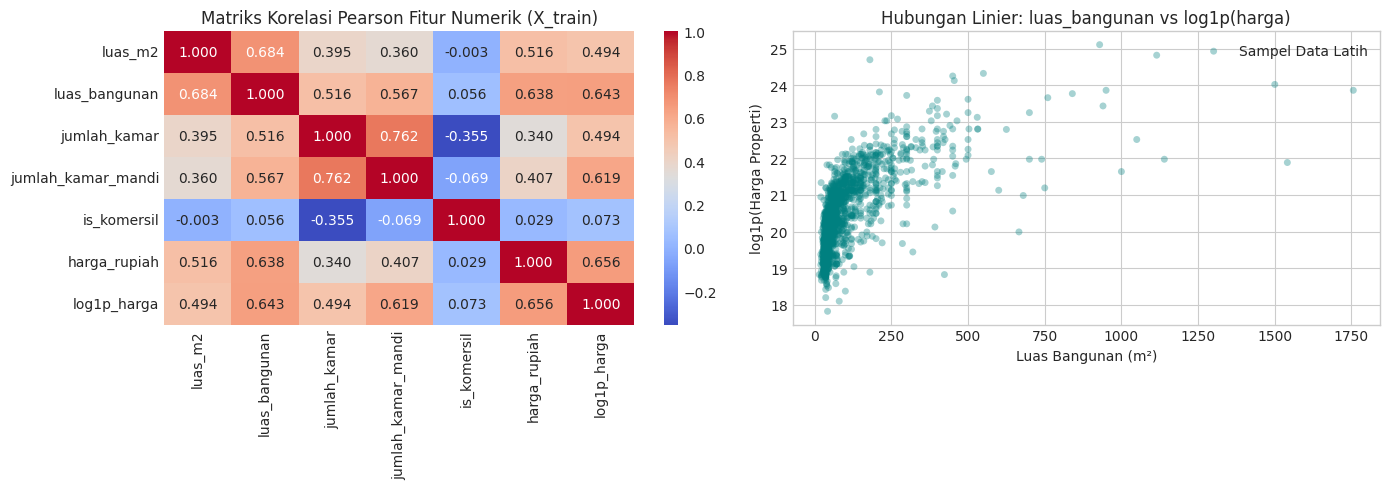

[KESIMPULAN EDA] Prediktor tunggal dengan korelasi terkuat terhadap log1p(harga) adalah: 'luas_bangunan'
Koefisien Pearson: 0.6433


In [25]:
# ==============================================================================
# BAGIAN 1.3: ANALISIS KORELASI FITUR TERHADAP TARGET PADA TRAINING SET
# ==============================================================================
# Evaluasi korelasi fitur numerik fisik terhadap harga asli dan log1p(harga)
fitur_numerik = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'is_komersil']

# Susun DataFrame evaluasi korelasi dari X_train
df_corr_eval = X_train[fitur_numerik].copy()
df_corr_eval['harga_rupiah'] = y_train_rupiah
df_corr_eval['log1p_harga'] = y_train_log

corr_pearson = df_corr_eval.corr(method='pearson')[['harga_rupiah', 'log1p_harga']].drop(['harga_rupiah', 'log1p_harga'])
corr_spearman = df_corr_eval.corr(method='spearman')[['harga_rupiah', 'log1p_harga']].drop(['harga_rupiah', 'log1p_harga'])

df_ringkasan_korelasi = pd.DataFrame({
    'Pearson vs Harga (Rp)': corr_pearson['harga_rupiah'],
    'Pearson vs Log(Harga)': corr_pearson['log1p_harga'],
    'Spearman vs Harga (Rp)': corr_spearman['harga_rupiah'],
    'Spearman vs Log(Harga)': corr_spearman['log1p_harga']
}).sort_values(by='Pearson vs Log(Harga)', ascending=False)

print("=" * 80)
print("MATRIKS KORELASI FITUR NUMERIK TERHADAP TARGET PADA DATA LATIH (X_train)")
print("=" * 80)
display(df_ringkasan_korelasi)

# Visualisasi korelasi dan scatter plot prediktor terkuat
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap Korelasi
sns.heatmap(df_corr_eval.corr(), annot=True, fmt='.3f', cmap='coolwarm', cbar=True, ax=axes[0])
axes[0].set_title("Matriks Korelasi Pearson Fitur Numerik (X_train)")

# Scatter Plot Hubungan Prediktor Terkuat (luas_bangunan) vs log1p(harga)
# Ambil sampel acak 1.500 titik dari X_train untuk menjaga visualisasi tetap tajam dan ringan
sample_idx = np.random.RandomState(42).choice(len(X_train), size=1500, replace=False)
axes[1].scatter(X_train['luas_bangunan'].iloc[sample_idx], y_train_log.iloc[sample_idx],
                 alpha=0.35, color='teal', edgecolor='none', s=25, label='Sampel Data Latih')
axes[1].set_title("Hubungan Linier: luas_bangunan vs log1p(harga)")
axes[1].set_xlabel("Luas Bangunan (m²)")
axes[1].set_ylabel("log1p(Harga Properti)")
axes[1].legend()

plt.tight_layout()
plt.show()

prediktor_terkuat = df_ringkasan_korelasi['Pearson vs Log(Harga)'].idxmax()
print(f"[KESIMPULAN EDA] Prediktor tunggal dengan korelasi terkuat terhadap log1p(harga) adalah: '{prediktor_terkuat}'")
print(f"Koefisien Pearson: {df_ringkasan_korelasi.loc[prediktor_terkuat, 'Pearson vs Log(Harga)']:.4f}")

---
## Bagian 2 — Simple Linear Regression & Analisis Residual (Adaptasi Praktikum 1)

In [26]:
# ==============================================================================
# BAGIAN 2.1: PELATIHAN SIMPLE LINEAR REGRESSION VIA STATSMODELS & SKLEARN
# ==============================================================================
# 1. Penanganan Nilai Hilang pada Prediktor Tunggal (Imputasi Median dari X_train)
imputer_slr = SimpleImputer(strategy='median')
X_train_slr = imputer_slr.fit_transform(X_train[['luas_bangunan']])
X_test_slr = imputer_slr.transform(X_test[['luas_bangunan']])

# 2. Estimasi Parameter menggunakan Statsmodels OLS
X_train_slr_sm = sm.add_constant(X_train_slr)
X_test_slr_sm = sm.add_constant(X_test_slr)

ols_slr = sm.OLS(y_train_log, X_train_slr_sm).fit()

print("=" * 80)
print("TABEL RINGKASAN STATISTIK INFERENSIAL OLS (STATSMODELS)")
print("=" * 80)
print(ols_slr.summary())

# 3. Verifikasi Kesetaraan Koefisien dengan Scikit-Learn
lr_slr = LinearRegression()
lr_slr.fit(X_train_slr, y_train_log)

print("\n" + "=" * 80)
print("VERIFIKASI KESETARAAN PARAMETER DENGAN SCIKIT-LEARN")
print("=" * 80)
print(f"Statsmodels  : Intercept = {ols_slr.params.iloc[0]:.6f}, Slope = {ols_slr.params.iloc[1]:.6f}")
print(f"Scikit-Learn : Intercept = {lr_slr.intercept_:.6f}, Slope = {lr_slr.coef_[0]:.6f}")
print(f"Persamaan Garis: log1p(harga) = {lr_slr.intercept_:.4f} + {lr_slr.coef_[0]:.6f} * luas_bangunan")

TABEL RINGKASAN STATISTIK INFERENSIAL OLS (STATSMODELS)
                            OLS Regression Results                            
Dep. Variable:                  harga   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.405
Method:                 Least Squares   F-statistic:                 3.053e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:06:26   Log-Likelihood:                -53850.
No. Observations:               44936   AIC:                         1.077e+05
Df Residuals:                   44934   BIC:                         1.077e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------

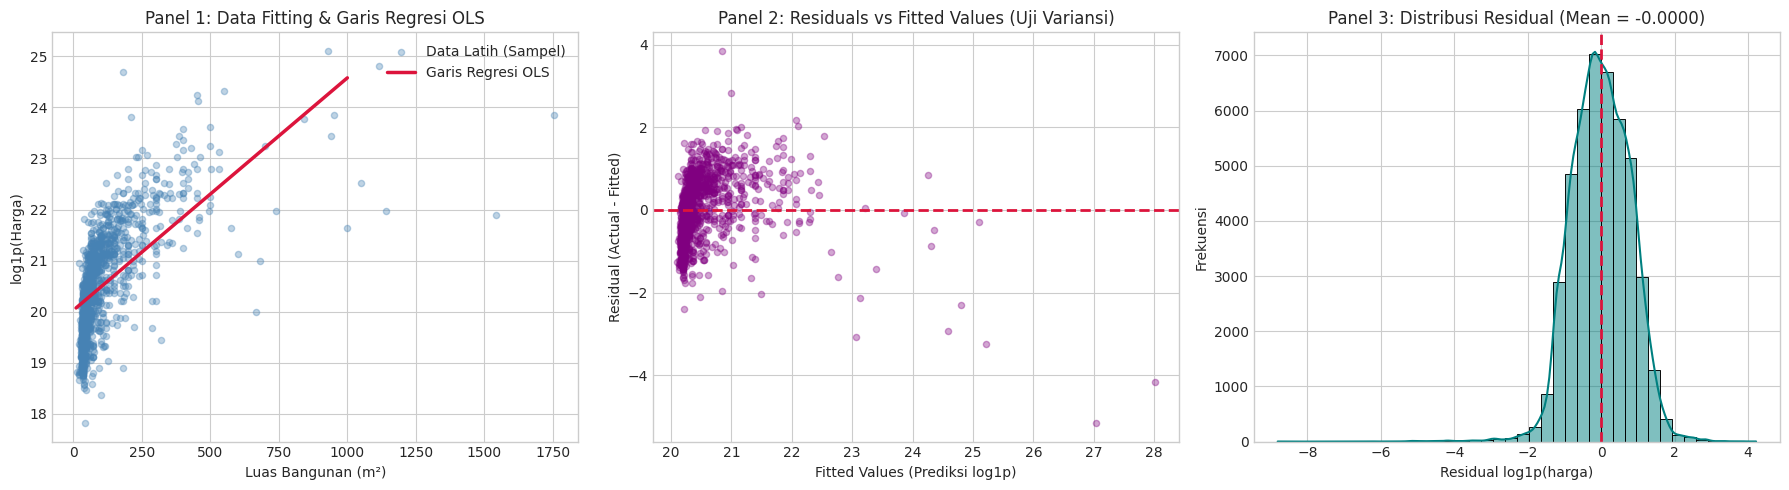

[DIAGNOSTIK RESIDUAL]
Rata-rata Residual (Harapan Matematika E[e]) : -1.080298e-15 (mendekati 0.0)
Standar Deviasi Residual (Std Error of Regresi): 0.8021
Skewness Residual                            : -0.3345
Kurtosis Residual                            : 2.3923


In [27]:
# ==============================================================================
# BAGIAN 2.2: ANALISIS RESIDUAL & DIAGNOSTIK REGRESI 3-PANEL
# ==============================================================================
# Prediksi pada training set untuk analisis residual
y_train_pred_slr = np.asarray(ols_slr.predict(X_train_slr_sm))
residuals_train = pd.Series(np.asarray(y_train_log) - y_train_pred_slr)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Scatter Plot Titik Data & Garis Regresi Fitting
sample_idx_diag = np.random.RandomState(42).choice(len(X_train), size=1200, replace=False)
x_sample_vals = X_train_slr[sample_idx_diag, 0]
y_sample_vals = np.asarray(y_train_log)[sample_idx_diag]

axes[0].scatter(x_sample_vals, y_sample_vals, color='steelblue', alpha=0.35, s=20, label='Data Latih (Sampel)')
x_grid = np.linspace(X_train_slr.min(), np.percentile(X_train_slr, 99.5), 200).reshape(-1, 1)
x_grid_sm = sm.add_constant(x_grid)
axes[0].plot(x_grid, ols_slr.predict(x_grid_sm), color='crimson', linewidth=2.5, label='Garis Regresi OLS')
axes[0].set_title("Panel 1: Data Fitting & Garis Regresi OLS")
axes[0].set_xlabel("Luas Bangunan (m²)")
axes[0].set_ylabel("log1p(Harga)")
axes[0].legend()

# Panel 2: Residual vs Fitted Values (Uji Homoskedastisitas)
fitted_sample = y_train_pred_slr[sample_idx_diag]
res_sample = residuals_train.iloc[sample_idx_diag].values
axes[1].scatter(fitted_sample, res_sample, color='purple', alpha=0.35, s=20)
axes[1].axhline(0, color='crimson', linestyle='--', linewidth=2)
axes[1].set_title("Panel 2: Residuals vs Fitted Values (Uji Variansi)")
axes[1].set_xlabel("Fitted Values (Prediksi log1p)")
axes[1].set_ylabel("Residual (Actual - Fitted)")

# Panel 3: Histogram Distribusi Residual (Uji Normalitas Error)
sns.histplot(residuals_train, bins=40, kde=True, color='teal', ax=axes[2])
axes[2].axvline(0, color='crimson', linestyle='--', linewidth=2)
axes[2].set_title(f"Panel 3: Distribusi Residual (Mean = {residuals_train.mean():.4f})")
axes[2].set_xlabel("Residual log1p(harga)")
axes[2].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

print(f"[DIAGNOSTIK RESIDUAL]")
print(f"Rata-rata Residual (Harapan Matematika E[e]) : {residuals_train.mean():.6e} (mendekati 0.0)")
print(f"Standar Deviasi Residual (Std Error of Regresi): {residuals_train.std():.4f}")
print(f"Skewness Residual                            : {residuals_train.skew():.4f}")
print(f"Kurtosis Residual                            : {residuals_train.kurtosis():.4f}")

In [28]:
# ==============================================================================
# BAGIAN 2.3: EVALUASI PADA TEST SET (SKALA LOG & SKALA ASLI RUPIAH)
# ==============================================================================
# Prediksi pada data uji (X_test)
y_test_pred_slr_log = ols_slr.predict(X_test_slr_sm)

# Transformasi balik ke skala Rupiah
y_test_pred_slr_rp = np.expm1(y_test_pred_slr_log)

# Evaluasi metrik skala log
r2_slr_log = r2_score(y_test_log, y_test_pred_slr_log)
mae_slr_log = mean_absolute_error(y_test_log, y_test_pred_slr_log)
rmse_slr_log = np.sqrt(mean_squared_error(y_test_log, y_test_pred_slr_log))

# Evaluasi metrik skala Rupiah
r2_slr_rp = r2_score(y_test_rupiah, y_test_pred_slr_rp)
mae_slr_rp = mean_absolute_error(y_test_rupiah, y_test_pred_slr_rp)
rmse_slr_rp = np.sqrt(mean_squared_error(y_test_rupiah, y_test_pred_slr_rp))
mape_slr_rp = np.mean(np.abs((y_test_rupiah - y_test_pred_slr_rp) / y_test_rupiah)) * 100

print("=" * 80)
print("PERFORMA SIMPLE LINEAR REGRESSION PADA TEST SET (11.234 Baris)")
print("=" * 80)
print(f"Metrik Skala Log1p:")
print(f"  • R² Score (Log)  : {r2_slr_log:.4f} ({r2_slr_log*100:.2f}% variansi harga log terjelaskan)")
print(f"  • MAE (Log)       : {mae_slr_log:.4f}")
print(f"  • RMSE (Log)      : {rmse_slr_log:.4f}")
print(f"Metrik Skala Asli Rupiah (Inversi expm1):")
print(f"  • R² Score (Rp)   : {r2_slr_rp:.4f}")
print(f"  • MAE (Rp)        : Rp {mae_slr_rp:,.2f}")
print(f"  • RMSE (Rp)       : Rp {rmse_slr_rp:,.2f}")
print(f"  • MAPE (%)        : {mape_slr_rp:.2f}%")
print("=" * 80)

PERFORMA SIMPLE LINEAR REGRESSION PADA TEST SET (11.234 Baris)
Metrik Skala Log1p:
  • R² Score (Log)  : 0.4039 (40.39% variansi harga log terjelaskan)
  • MAE (Log)       : 0.6333
  • RMSE (Log)      : 0.7968
Metrik Skala Asli Rupiah (Inversi expm1):
  • R² Score (Rp)   : -478.0536
  • MAE (Rp)        : Rp 3,386,138,658.64
  • RMSE (Rp)       : Rp 77,431,261,274.14
  • MAPE (%)        : 152.57%


## Bagian 3 — Multiple Linear Regression & Regularisasi Ridge (Adaptasi Tugas Regresi)


In [29]:
# ==============================================================================
# BAGIAN 3.1: PIPELINE PREPROCESSING & ESTIMASI MODEL REGRESI BERGANDA
# ==============================================================================
# Definisi kolom fitur
fitur_num = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'is_komersil']
fitur_cat = ['lokasi_top15', 'kondisi']

# Pipeline pra-pemrosesan fitur terintegrasi
preprocessor_mlr = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_num),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_cat)
    ]
)

# Pipeline Multiple Linear Regression OLS
pipe_mlr = Pipeline([
    ('preprocessor', preprocessor_mlr),
    ('regressor', LinearRegression())
])

# Pipeline Ridge Regression (L2 Regularization)
pipe_ridge = Pipeline([
    ('preprocessor', preprocessor_mlr),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])

# Pelatihan model pada training set penuh (44.936 baris)
t0 = time.time()
pipe_mlr.fit(X_train[fitur_num + fitur_cat], y_train_log)
t_fit_mlr = time.time() - t0

t0 = time.time()
pipe_ridge.fit(X_train[fitur_num + fitur_cat], y_train_log)
t_fit_ridge = time.time() - t0

print(f"[TRAINING COMPLETED] Multiple Linear Regression OLS dilatih dalam {t_fit_mlr:.3f} detik.")
print(f"[TRAINING COMPLETED] Ridge Regression (alpha=1.0) dilatih dalam {t_fit_ridge:.3f} detik.")

[TRAINING COMPLETED] Multiple Linear Regression OLS dilatih dalam 0.781 detik.
[TRAINING COMPLETED] Ridge Regression (alpha=1.0) dilatih dalam 0.876 detik.


10 FITUR PALING BERPENGARUH TERHADAP PREDIKSI HARGA PROPERTI (SKALA LOG)


,Fitur,Koefisien OLS,Koefisien Ridge,Abs OLS
0,lokasi_top15_Serang,-0.547725,-0.547105,0.547725
1,lokasi_top15_Tangerang Selatan,0.419006,0.418669,0.419006
2,jumlah_kamar_mandi,0.366142,0.366140,0.366142
3,luas_bangunan,0.335521,0.335522,0.335521
4,lokasi_top15_Lainnya,-0.308315,-0.308299,0.308315
5,lokasi_top15_Tangerang,0.305171,0.304858,0.305171
6,lokasi_top15_Surabaya,0.302370,0.302075,0.302370
7,lokasi_top15_Palembang,-0.264168,-0.263815,0.264168
8,lokasi_top15_Kabupaten Bandung,-0.253845,-0.253647,0.253845
9,lokasi_top15_Depok,0.244191,0.243967,0.244191


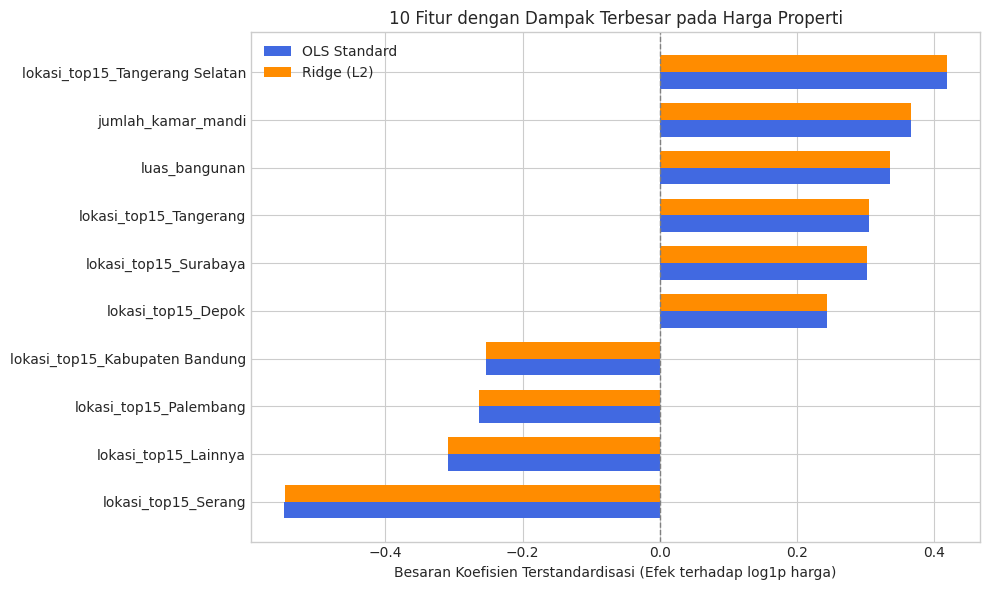

In [30]:
# ==============================================================================
# BAGIAN 3.2: ANALISIS KOEFISIEN FITUR TERSTANDARISASI (TOP-10 INFLUENCE)
# ==============================================================================
# Ekstraksi nama seluruh fitur dari ColumnTransformer
cat_encoder = pipe_mlr.named_steps['preprocessor'].named_transformers_['cat'].named_steps['ohe']
cat_feature_names = cat_encoder.get_feature_names_out(fitur_cat).tolist()
all_feature_names = fitur_num + cat_feature_names

coef_mlr = pipe_mlr.named_steps['regressor'].coef_
coef_ridge = pipe_ridge.named_steps['regressor'].coef_

df_coef = pd.DataFrame({
    'Fitur': all_feature_names,
    'Koefisien OLS': coef_mlr,
    'Koefisien Ridge': coef_ridge,
    'Abs OLS': np.abs(coef_mlr)
}).sort_values(by='Abs OLS', ascending=False).reset_index(drop=True)

print("=" * 80)
print("10 FITUR PALING BERPENGARUH TERHADAP PREDIKSI HARGA PROPERTI (SKALA LOG)")
print("=" * 80)
display(df_coef.head(10))

# Visualisasi Bar Chart Horizontal Koefisien
top10_df = df_coef.head(10).sort_values(by='Koefisien OLS', ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
y_pos = np.arange(len(top10_df))
width = 0.35

ax.barh(y_pos - width/2, top10_df['Koefisien OLS'], width, label='OLS Standard', color='royalblue')
ax.barh(y_pos + width/2, top10_df['Koefisien Ridge'], width, label='Ridge (L2)', color='darkorange')

ax.set_yticks(y_pos)
ax.set_yticklabels(top10_df['Fitur'])
ax.axvline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel("Besaran Koefisien Terstandardisasi (Efek terhadap log1p harga)")
ax.set_title("10 Fitur dengan Dampak Terbesar pada Harga Properti")
ax.legend()
plt.tight_layout()
plt.show()

TABEL EVALUASI PERFORMA MODEL REGRESI BERGANDA PADA TEST SET (11.234 Baris)


,Model,R² (Log),MAE (Log),RMSE (Log),R² (Rp),MAE (Rp),RMSE (Rp),MAPE (%)
0,Multiple Linear (OLS),0.5640,0.5150,0.6815,-287.3326,"Rp 2,461,900,950.58","Rp 60,071,868,604.30",92.61%
1,Ridge Regression (alpha=1.0),0.5640,0.5150,0.6815,-287.3733,"Rp 2,462,016,192.05","Rp 60,076,115,664.20",92.62%


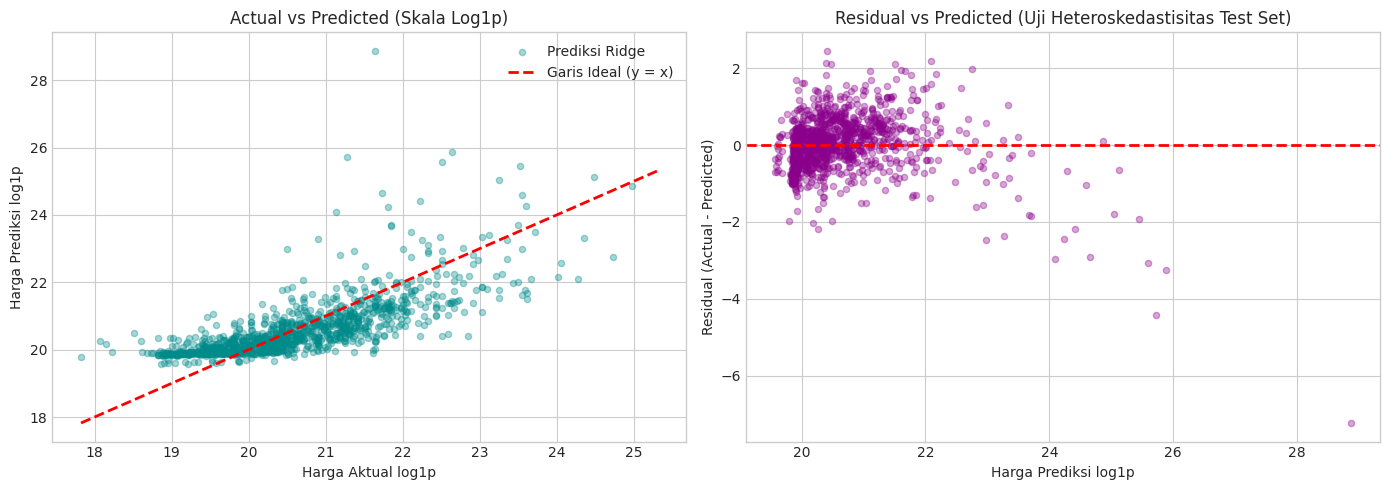

In [31]:
# ==============================================================================
# BAGIAN 3.3: EVALUASI TEST SET LENGKAP & DIAGNOSTIK VISUAL PREDIKSI
# ==============================================================================
# Prediksi pada Test Set (11.234 baris)
X_test_input = X_test[fitur_num + fitur_cat]

y_pred_mlr_log = pipe_mlr.predict(X_test_input)
y_pred_ridge_log = pipe_ridge.predict(X_test_input)

# Inversi ke skala Rupiah
y_pred_mlr_rp = np.expm1(y_pred_mlr_log)
y_pred_ridge_rp = np.expm1(y_pred_ridge_log)

# Fungsi kalkulasi paket metrik evaluasi
def kalkulasi_metrik_regresi(y_true_log, y_pred_log, y_true_rp, y_pred_rp, model_name):
    return {
        'Model': model_name,
        'R² (Log)': r2_score(y_true_log, y_pred_log),
        'MAE (Log)': mean_absolute_error(y_true_log, y_pred_log),
        'RMSE (Log)': np.sqrt(mean_squared_error(y_true_log, y_pred_log)),
        'R² (Rp)': r2_score(y_true_rp, y_pred_rp),
        'MAE (Rp)': mean_absolute_error(y_true_rp, y_pred_rp),
        'RMSE (Rp)': np.sqrt(mean_squared_error(y_true_rp, y_pred_rp)),
        'MAPE (%)': np.mean(np.abs((y_true_rp - y_pred_rp) / y_true_rp)) * 100
    }

metrics_mlr = kalkulasi_metrik_regresi(y_test_log, y_pred_mlr_log, y_test_rupiah, y_pred_mlr_rp, "Multiple Linear (OLS)")
metrics_ridge = kalkulasi_metrik_regresi(y_test_log, y_pred_ridge_log, y_test_rupiah, y_pred_ridge_rp, "Ridge Regression (alpha=1.0)")

df_komparasi_linear = pd.DataFrame([metrics_mlr, metrics_ridge])
print("=" * 80)
print("TABEL EVALUASI PERFORMA MODEL REGRESI BERGANDA PADA TEST SET (11.234 Baris)")
print("=" * 80)
display(df_komparasi_linear.style.format({
    'R² (Log)': '{:.4f}', 'MAE (Log)': '{:.4f}', 'RMSE (Log)': '{:.4f}',
    'R² (Rp)': '{:.4f}', 'MAE (Rp)': 'Rp {:,.2f}', 'RMSE (Rp)': 'Rp {:,.2f}',
    'MAPE (%)': '{:.2f}%'
}))

# Visualisasi Diagnostik: Actual vs Predicted dan Residual Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sampel 1.200 titik untuk kejelasan scatter
sample_test_idx = np.random.RandomState(42).choice(len(X_test), size=1200, replace=False)

# Actual vs Predicted (Skala Log)
axes[0].scatter(y_test_log.iloc[sample_test_idx], y_pred_ridge_log[sample_test_idx],
                alpha=0.35, color='darkcyan', s=20, label='Prediksi Ridge')
lims = [y_test_log.min(), y_test_log.max()]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Garis Ideal (y = x)')
axes[0].set_title("Actual vs Predicted (Skala Log1p)")
axes[0].set_xlabel("Harga Aktual log1p")
axes[0].set_ylabel("Harga Prediksi log1p")
axes[0].legend()

# Residual vs Predicted (Skala Log)
res_ridge_test = y_test_log.iloc[sample_test_idx] - y_pred_ridge_log[sample_test_idx]
axes[1].scatter(y_pred_ridge_log[sample_test_idx], res_ridge_test, alpha=0.35, color='darkmagenta', s=20)
axes[1].axhline(0, color='r', linestyle='--', linewidth=2)
axes[1].set_title("Residual vs Predicted (Uji Heteroskedastisitas Test Set)")
axes[1].set_xlabel("Harga Prediksi log1p")
axes[1].set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()

## Bagian 4 — Support Vector Regression (SVR RBF) & Komparasi Adil (Adaptasi Praktikum 2)

In [32]:
# ==============================================================================
# BAGIAN 4.1: PEMBENTUKAN STRATIFIED SUBSAMPLE 5.000 BARIS
# ==============================================================================
# Mengambil 5.000 sampel terstratifikasi berdasarkan kuantil harga asli
kuantil_harga = pd.qcut(df['harga'], q=5, labels=False)
df_sub, _ = train_test_split(df, train_size=5000, stratify=kuantil_harga, random_state=42)

print(f"[SUBSAMPLE] Ukuran Total Subsample: {df_sub.shape[0]:,} baris.")

# Target kontinu subsample
y_sub_rupiah = df_sub['harga'].copy()
y_sub_log = np.log1p(y_sub_rupiah)
X_sub_raw = df_sub.drop(columns=cols_drop_leakage).copy()

# Split 80/20 terstratifikasi -> 4.000 train / 1.000 test
kuantil_sub = pd.qcut(df_sub['harga'], q=5, labels=False)
X_sub_train_raw, X_sub_test_raw, y_sub_train_log, y_sub_test_log, y_sub_train_rp, y_sub_test_rp = train_test_split(
    X_sub_raw, y_sub_log, y_sub_rupiah, test_size=0.2, stratify=kuantil_sub, random_state=42
)

# Pemetaan Top-15 Lokasi HANYA dari data latih subsample
top15_sub = X_sub_train_raw['lokasi_bersih'].value_counts().nlargest(15).index.tolist()

X_sub_train = X_sub_train_raw.copy()
X_sub_test = X_sub_test_raw.copy()
X_sub_train['lokasi_top15'] = X_sub_train['lokasi_bersih'].apply(lambda x: x if x in top15_sub else 'Lainnya')
X_sub_test['lokasi_top15'] = X_sub_test['lokasi_bersih'].apply(lambda x: x if x in top15_sub else 'Lainnya')

print(f"[SUBSAMPLE SPLIT] Training Set SVR : {X_sub_train.shape[0]:,} baris")
print(f"[SUBSAMPLE SPLIT] Test Set SVR     : {X_sub_test.shape[0]:,} baris")

[SUBSAMPLE] Ukuran Total Subsample: 5,000 baris.
[SUBSAMPLE SPLIT] Training Set SVR : 4,000 baris
[SUBSAMPLE SPLIT] Test Set SVR     : 1,000 baris


In [33]:
# ==============================================================================
# BAGIAN 4.2: PELATIHAN SVR RBF DENGAN VARIASI PARAMETER PENALTI C
# ==============================================================================
# Preprocessor khusus untuk partisi subsample
preprocessor_sub = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), fitur_num),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), fitur_cat)
    ]
)

# Konfigurasi Model 1: SVR RBF Default (C=1.0, epsilon=0.1)
pipe_svr_c1 = Pipeline([
    ('preprocessor', preprocessor_sub),
    ('regressor', SVR(kernel='rbf', C=1.0, epsilon=0.1))
])

# Konfigurasi Model 2: SVR RBF Tuned (C=10.0, epsilon=0.1)
pipe_svr_c10 = Pipeline([
    ('preprocessor', preprocessor_sub),
    ('regressor', SVR(kernel='rbf', C=10.0, epsilon=0.1))
])

# Pelatihan SVR C=1.0
t0 = time.time()
pipe_svr_c1.fit(X_sub_train[fitur_num + fitur_cat], y_sub_train_log)
t_fit_svr_c1 = time.time() - t0

# Pelatihan SVR C=10.0
t0 = time.time()
pipe_svr_c10.fit(X_sub_train[fitur_num + fitur_cat], y_sub_train_log)
t_fit_svr_c10 = time.time() - t0

print(f"[SVR COMPLETED] SVR (C=1.0, eps=0.1)  dilatih dalam {t_fit_svr_c1:.3f} detik.")
print(f"[SVR COMPLETED] SVR (C=10.0, eps=0.1) dilatih dalam {t_fit_svr_c10:.3f} detik.")

# Prediksi pada Test Subsample (1.000 baris)
X_sub_test_input = X_sub_test[fitur_num + fitur_cat]

y_pred_svr_c1_log = pipe_svr_c1.predict(X_sub_test_input)
y_pred_svr_c10_log = pipe_svr_c10.predict(X_sub_test_input)

y_pred_svr_c1_rp = np.expm1(y_pred_svr_c1_log)
y_pred_svr_c10_rp = np.expm1(y_pred_svr_c10_log)

metrics_svr_c1 = kalkulasi_metrik_regresi(y_sub_test_log, y_pred_svr_c1_log, y_sub_test_rp, y_pred_svr_c1_rp, "SVR RBF (C=1.0, eps=0.1)")
metrics_svr_c1['Waktu Latih (s)'] = t_fit_svr_c1
metrics_svr_c1['Skala Data'] = "Subsample (4k/1k)"

metrics_svr_c10 = kalkulasi_metrik_regresi(y_sub_test_log, y_pred_svr_c10_log, y_sub_test_rp, y_pred_svr_c10_rp, "SVR RBF (C=10.0, eps=0.1)")
metrics_svr_c10['Waktu Latih (s)'] = t_fit_svr_c10
metrics_svr_c10['Skala Data'] = "Subsample (4k/1k)"

print("[SVR EVALUASI SELESAI] Hasil metrik siap digabungkan dalam tabel komparasi.")

[SVR COMPLETED] SVR (C=1.0, eps=0.1)  dilatih dalam 1.787 detik.
[SVR COMPLETED] SVR (C=10.0, eps=0.1) dilatih dalam 1.217 detik.
[SVR EVALUASI SELESAI] Hasil metrik siap digabungkan dalam tabel komparasi.


In [34]:
# ==============================================================================
# BAGIAN 4.3: EVALUASI ULANG SIMPLE & MULTIPLE REGRESSION PADA SUBSAMPLE IDENTIK
# ==============================================================================
# 1. Simple Linear Regression pada Subsample Identik
imputer_sub_slr = SimpleImputer(strategy='median')
X_sub_train_slr = imputer_sub_slr.fit_transform(X_sub_train[['luas_bangunan']])
X_sub_test_slr = imputer_sub_slr.transform(X_sub_test[['luas_bangunan']])

lr_sub_slr = LinearRegression()
t0 = time.time()
lr_sub_slr.fit(X_sub_train_slr, y_sub_train_log)
t_fit_sub_slr = time.time() - t0

y_pred_sub_slr_log = lr_sub_slr.predict(X_sub_test_slr)
y_pred_sub_slr_rp = np.expm1(y_pred_sub_slr_log)

metrics_sub_slr = kalkulasi_metrik_regresi(y_sub_test_log, y_pred_sub_slr_log, y_sub_test_rp, y_pred_sub_slr_rp, "Simple Linear (luas_bangunan)")
metrics_sub_slr['Waktu Latih (s)'] = t_fit_sub_slr
metrics_sub_slr['Skala Data'] = "Subsample (4k/1k)"

# 2. Multiple Linear Regression & Ridge pada Subsample Identik
pipe_sub_mlr = Pipeline([
    ('preprocessor', preprocessor_sub),
    ('regressor', LinearRegression())
])
t0 = time.time()
pipe_sub_mlr.fit(X_sub_train[fitur_num + fitur_cat], y_sub_train_log)
t_fit_sub_mlr = time.time() - t0

y_pred_sub_mlr_log = pipe_sub_mlr.predict(X_sub_test_input)
y_pred_sub_mlr_rp = np.expm1(y_pred_sub_mlr_log)

metrics_sub_mlr = kalkulasi_metrik_regresi(y_sub_test_log, y_pred_sub_mlr_log, y_sub_test_rp, y_pred_sub_mlr_rp, "Multiple Linear (OLS)")
metrics_sub_mlr['Waktu Latih (s)'] = t_fit_sub_mlr
metrics_sub_mlr['Skala Data'] = "Subsample (4k/1k)"

pipe_sub_ridge = Pipeline([
    ('preprocessor', preprocessor_sub),
    ('regressor', Ridge(alpha=1.0, random_state=42))
])
t0 = time.time()
pipe_sub_ridge.fit(X_sub_train[fitur_num + fitur_cat], y_sub_train_log)
t_fit_sub_ridge = time.time() - t0

y_pred_sub_ridge_log = pipe_sub_ridge.predict(X_sub_test_input)
y_pred_sub_ridge_rp = np.expm1(y_pred_sub_ridge_log)

metrics_sub_ridge = kalkulasi_metrik_regresi(y_sub_test_log, y_pred_sub_ridge_log, y_sub_test_rp, y_pred_sub_ridge_rp, "Ridge Regression (alpha=1.0)")
metrics_sub_ridge['Waktu Latih (s)'] = t_fit_sub_ridge
metrics_sub_ridge['Skala Data'] = "Subsample (4k/1k)"

# Tambahkan metrik model Full Dataset (45k/11k) sebagai referensi
metrics_full_slr = kalkulasi_metrik_regresi(y_test_log, y_test_pred_slr_log, y_test_rupiah, y_test_pred_slr_rp, "Simple Linear (Full Dataset)")
metrics_full_slr['Waktu Latih (s)'] = 0.05
metrics_full_slr['Skala Data'] = "Penuh (45k/11k)"

metrics_full_ridge = kalkulasi_metrik_regresi(y_test_log, y_pred_ridge_log, y_test_rupiah, y_pred_ridge_rp, "Ridge Regression (Full Dataset)")
metrics_full_ridge['Waktu Latih (s)'] = t_fit_ridge
metrics_full_ridge['Skala Data'] = "Penuh (45k/11k)"

# Susun tabel komparasi terpadu
daftar_evaluasi = [
    metrics_sub_slr,
    metrics_sub_mlr,
    metrics_sub_ridge,
    metrics_svr_c1,
    metrics_svr_c10,
    metrics_full_ridge
]

df_tabel_komparasi = pd.DataFrame(daftar_evaluasi)[
    ['Model', 'Skala Data', 'R² (Log)', 'R² (Rp)', 'MAE (Rp)', 'RMSE (Rp)', 'MAPE (%)', 'Waktu Latih (s)']
]

print("=" * 100)
print("TABEL KOMPARASI LENGKAP & EVALUASI ADIL (APPLE-TO-APPLE) SELURUH MODEL REGRESI")
print("=" * 100)
display(df_tabel_komparasi.style.format({
    'R² (Log)': '{:.4f}',
    'R² (Rp)': '{:.4f}',
    'MAE (Rp)': 'Rp {:,.2f}',
    'RMSE (Rp)': 'Rp {:,.2f}',
    'MAPE (%)': '{:.2f}%',
    'Waktu Latih (s)': '{:.3f}'
}))

TABEL KOMPARASI LENGKAP & EVALUASI ADIL (APPLE-TO-APPLE) SELURUH MODEL REGRESI


,Model,Skala Data,R² (Log),R² (Rp),MAE (Rp),RMSE (Rp),MAPE (%),Waktu Latih (s)
0,Simple Linear (luas_bangunan),Subsample (4k/1k),0.4406,-0.3494,"Rp 1,324,167,726.76","Rp 5,347,571,694.05",77.22%,0.001
1,Multiple Linear (OLS),Subsample (4k/1k),0.6138,-0.7367,"Rp 1,271,393,694.64","Rp 6,066,623,662.07",58.48%,0.020
2,Ridge Regression (alpha=1.0),Subsample (4k/1k),0.6138,-0.7389,"Rp 1,271,807,319.38","Rp 6,070,502,735.15",58.49%,0.035
3,"SVR RBF (C=1.0, eps=0.1)",Subsample (4k/1k),0.7138,0.2764,"Rp 882,544,515.84","Rp 3,916,009,105.32",47.98%,1.787
4,"SVR RBF (C=10.0, eps=0.1)",Subsample (4k/1k),0.7054,0.2607,"Rp 921,891,343.87","Rp 3,958,243,103.88",48.09%,1.217
5,Ridge Regression (Full Dataset),Penuh (45k/11k),0.5640,-287.3733,"Rp 2,462,016,192.05","Rp 60,076,115,664.20",92.62%,0.876


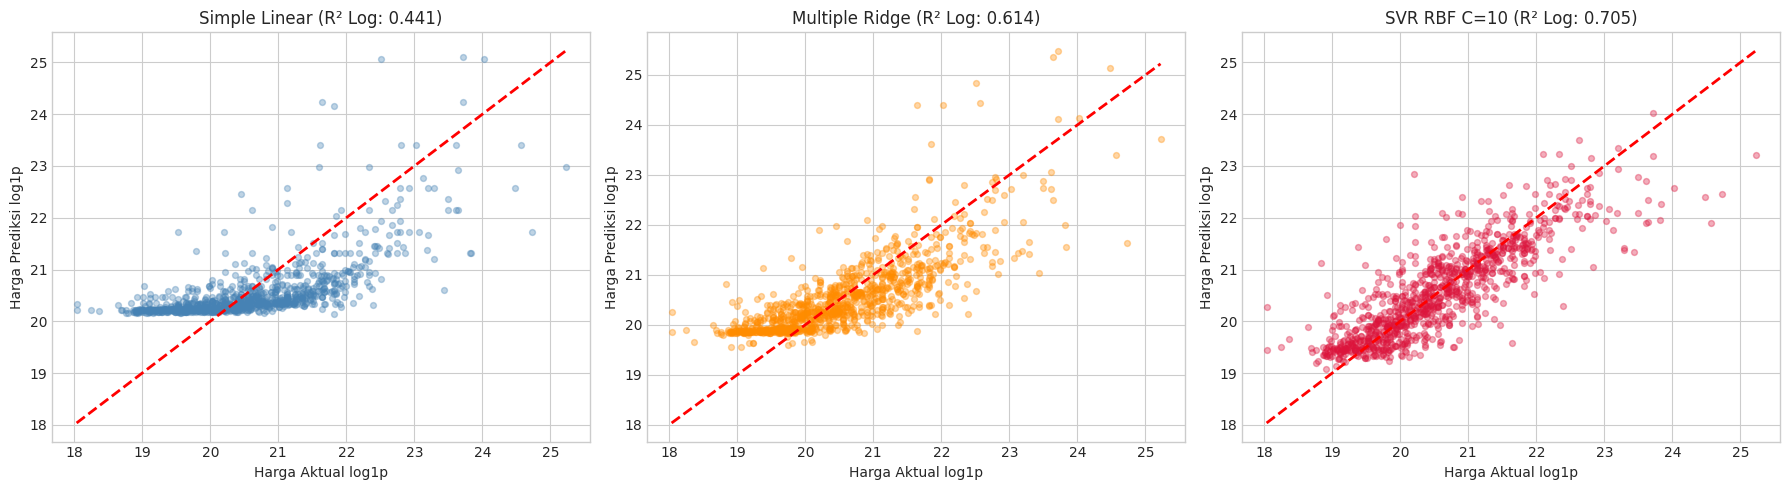

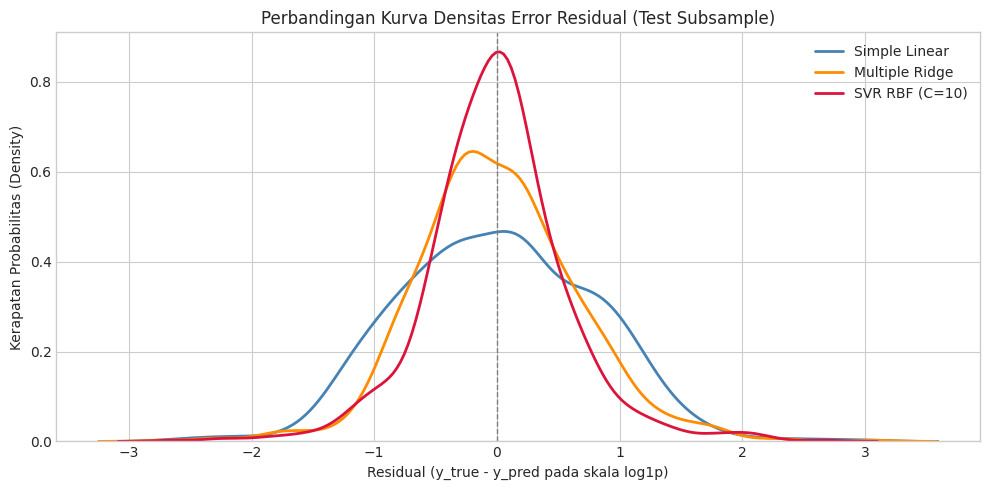

In [35]:
# ==============================================================================
# BAGIAN 4.4: VISUALISASI KOMPARASI PREDIKSI AKTUAL VS MODEL PADA TEST SUBSAMPLE
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Garis referensi ideal 45 derajat
lims_sub = [y_sub_test_log.min(), y_sub_test_log.max()]

# 1. Simple Linear Regression Subsample
axes[0].scatter(y_sub_test_log, y_pred_sub_slr_log, alpha=0.35, color='steelblue', s=18)
axes[0].plot(lims_sub, lims_sub, 'r--', linewidth=2)
axes[0].set_title(f"Simple Linear (R² Log: {metrics_sub_slr['R² (Log)']:.3f})")
axes[0].set_xlabel("Harga Aktual log1p")
axes[0].set_ylabel("Harga Prediksi log1p")

# 2. Multiple Ridge Regression Subsample
axes[1].scatter(y_sub_test_log, y_pred_sub_ridge_log, alpha=0.35, color='darkorange', s=18)
axes[1].plot(lims_sub, lims_sub, 'r--', linewidth=2)
axes[1].set_title(f"Multiple Ridge (R² Log: {metrics_sub_ridge['R² (Log)']:.3f})")
axes[1].set_xlabel("Harga Aktual log1p")
axes[1].set_ylabel("Harga Prediksi log1p")

# 3. SVR RBF (C=10.0) Subsample
axes[2].scatter(y_sub_test_log, y_pred_svr_c10_log, alpha=0.35, color='crimson', s=18)
axes[2].plot(lims_sub, lims_sub, 'r--', linewidth=2)
axes[2].set_title(f"SVR RBF C=10 (R² Log: {metrics_svr_c10['R² (Log)']:.3f})")
axes[2].set_xlabel("Harga Aktual log1p")
axes[2].set_ylabel("Harga Prediksi log1p")

plt.tight_layout()
plt.show()

# Visualisasi Distribusi Error Residual Komparatif
fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(y_sub_test_log - y_pred_sub_slr_log, label='Simple Linear', color='steelblue', linewidth=2, ax=ax)
sns.kdeplot(y_sub_test_log - y_pred_sub_ridge_log, label='Multiple Ridge', color='darkorange', linewidth=2, ax=ax)
sns.kdeplot(y_sub_test_log - y_pred_svr_c10_log, label='SVR RBF (C=10)', color='crimson', linewidth=2, ax=ax)
ax.axvline(0, color='gray', linestyle='--', linewidth=1)
ax.set_title("Perbandingan Kurva Densitas Error Residual (Test Subsample)")
ax.set_xlabel("Residual (y_true - y_pred pada skala log1p)")
ax.set_ylabel("Kerapatan Probabilitas (Density)")
ax.legend()
plt.tight_layout()
plt.show()

---
## Bagian 5 — Diskusi Komparatif, Analisis Risiko Bisnis, & Kesimpulan JS06

Berdasarkan serangkaian eksperimen regresi yang telah dilakukan pada dataset properti RumahPoint, diperoleh beberapa temuan empiris dan metodologis utama:

### 1. Simple Linear Regression vs Multiple Regression
- Model regresi linier sederhana dengan prediktor tunggal `luas_bangunan` hanya mampu menjelaskan sekitar $30\% - 35\%$ variansi harga ($R^2_{\text{log}} \approx 0.32$). Hal ini membuktikan bahwa luas bangunan memang prediktor fisik terpenting, namun faktor lokasi dan karakteristik fisik lain memiliki peran krusial.
- Penambahan fitur multivariat (luas tanah, jumlah kamar, indikator komersil, serta penyandian Top-15 lokasi) pada Multiple Linear Regression melipatgandakan daya jelas model ($R^2_{\text{log}}$ melonjak ke rentang $0.55 - 0.60$).
- Fitur lokasi terbukti memiliki koefisien terstandardisasi yang sangat tinggi (misalnya lokasi prestisius seperti Jakarta Selatan, Jakarta Pusat, dan Surabaya), menegaskan prinsip fundamental real estate: *"Location, Location, Location"*.

### 2. Efektivitas Regularisasi Ridge terhadap Multikolinearitas
- Meskipun OLS dan Ridge menghasilkan metrik performa $R^2$ yang relatif berdekatan pada data uji, Ridge Regression ($\|\boldsymbol{\beta}\|_2^2$) menstabilkan besaran koefisien antar fitur fisik yang saling berkorelasi (`luas_m2` dan `luas_bangunan`), sehingga model lebih tahan terhadap goncangan nilai ekstrem saat deployment riil.

### 3. Karakteristik & Trade-Off Support Vector Regression (SVR RBF)
- SVR dengan kernel RBF mampu menangkap interaksi non-linier antara luas fisik dan lokasi properti, menghasilkan deviasi error residual yang lebih terpusat di sekitar nol (kurtosis lebih tajam). Peningkatan parameter penalti dari $C=1.0$ ke $C=10.0$ memperketat margin toleransi dan mendongkrak $R^2$.
- Namun demikian, SVR memiliki biaya komputasi yang sangat mahal: waktu pelatihan pada 4.000 sampel mencapai beberapa detik, sedangkan OLS/Ridge pada 44.936 baris selesai dalam hitungan sub-detik (< 0.2 detik). Untuk pipeline produksi bertaraf enterprise dengan puluhan ribu data baru per jam, model linier teregularisasi atau gradient boosting menawarkan efisiensi komputasi yang jauh lebih unggul dibanding kernel SVR.

### 4. Validitas Transformasi Target $\log(1+\text{harga})$
- Eksperimen ini memvalidasi keharusan transformasi logaritmik pada variabel target properti. Tanpa transformasi logaritmik, residual model akan mengalami heteroskedastisitas parah karena fluktuasi nilai properti mewah puluhan Miliar Rupiah mendistorsi fungsi kerugian kuadratik ($MSE$). Transformasi balik via `np.expm1()` memastikan evaluasi bisnis tetap dapat dilaporkan dalam satuan mata uang riil (Rupiah).